<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/1_foundations/dynamics_relativity/make_figures_ch04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Dynamics and Relativity* — `make_figures_ch04.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Dynamics & Relativity — Chapter 4 Figure Generator

Generates all figures for **Chapter 4: Central Forces** lecture slides.

| # | Function | Slide |
|---|---|---|
| 1 | `fig_polar_coords` | §4.1 — Polar coordinate basis vectors $\hat{\mathbf{r}},\hat{\boldsymbol{\theta}}$ |
| 2 | `fig_veff` | §4.2 — Effective potential for inverse-square force |
| 3 | `fig_veff_stability` | §4.2.2 — Stability: $n=1$ (stable) vs $n=3$ (unstable) |
| 4 | `fig_conics` | §4.3.1 — Conic sections: ellipse, parabola, hyperbola |
| 5 | `fig_ellipse` | §4.3.1 — Elliptical orbit with labelled geometry |
| 6 | `fig_kepler2` | §4.3.2 — Kepler's 2nd law: equal areas |
| 7 | `fig_precession` | §4.3.3 — Orbital precession (GR correction) |
| 8 | `fig_scattering` | §4.4 — Scattering geometry: impact parameter $b$, angle $\phi$ |
| 9 | `fig_rutherford` | §4.4.1 — Rutherford scattering trajectories + $\phi(b)$ curve |

All figures are saved to `figures/` and downloaded as a zip at the end.

## 0. Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Arc

os.makedirs('figures', exist_ok=True)

# ── Colour palette (matches dark revealjs theme) ──────────────────────────────
DARK_BG = '#1a1a2e'
BLUE    = '#7ec8e3'
YELLOW  = '#f9c74f'
GREEN   = '#90ee90'
RED     = '#e07070'
DIM     = '#aaaaaa'
WHITE   = '#ffffff'

def base_style():
    plt.rcParams.update({
        'figure.facecolor': DARK_BG, 'axes.facecolor':   DARK_BG,
        'axes.edgecolor':   DIM,     'axes.labelcolor':  WHITE,
        'xtick.color':      DIM,     'ytick.color':      DIM,
        'text.color':       WHITE,   'grid.color':       '#333355',
        'grid.linestyle':   '--',    'grid.alpha':       0.5,
        'font.family':      'sans-serif',
        'font.size':        12,
        'mathtext.fontset': 'stix',
    })

print('Setup complete. Figures will be saved to figures/')

Setup complete. Figures will be saved to figures/


---
## Fig 1 — Polar coordinate basis vectors $\hat{\mathbf{r}},\, \hat{\boldsymbol{\theta}}$

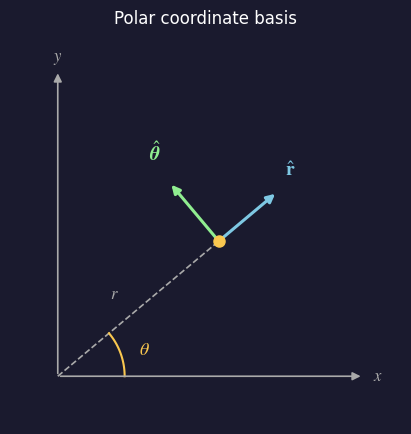

✓ figures/fig_polar_coords.png


In [2]:
def fig_polar_coords():
    base_style()
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.set_aspect('equal'); ax.axis('off')

    theta = np.radians(40)
    r = 2.2
    px, py = r*np.cos(theta), r*np.sin(theta)

    # coordinate axes
    ax.annotate('', xy=(3.2, 0), xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', color=DIM, lw=1.2))
    ax.annotate('', xy=(0, 3.2), xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', color=DIM, lw=1.2))
    ax.text(3.3, 0,   r'$x$', color=DIM, fontsize=12, va='center')
    ax.text(0,   3.3, r'$y$', color=DIM, fontsize=12, ha='center')

    # r line (dashed)
    ax.plot([0, px], [0, py], color=DIM, lw=1.2, ls='--')
    ax.text(px/2 - 0.3, py/2 + 0.1, r'$r$', color=DIM, fontsize=12)

    # particle position
    ax.plot(px, py, 'o', color=YELLOW, ms=8, zorder=5)

    # r_hat arrow
    rhat = np.array([np.cos(theta), np.sin(theta)])
    ax.annotate('', xy=(px + 0.8*rhat[0], py + 0.8*rhat[1]),
                xytext=(px, py),
                arrowprops=dict(arrowstyle='-|>', color=BLUE, lw=2.2))
    ax.text(px + 0.9*rhat[0], py + 0.9*rhat[1] + 0.1,
            r'$\hat{\mathbf{r}}$', color=BLUE, fontsize=14)

    # theta_hat arrow (perpendicular to r_hat)
    that = np.array([-np.sin(theta), np.cos(theta)])
    ax.annotate('', xy=(px + 0.8*that[0], py + 0.8*that[1]),
                xytext=(px, py),
                arrowprops=dict(arrowstyle='-|>', color=GREEN, lw=2.2))
    ax.text(px + 0.9*that[0] - 0.15, py + 0.9*that[1] + 0.15,
            r'$\hat{\boldsymbol{\theta}}$', color=GREEN, fontsize=14)

    # theta arc
    angs = np.linspace(0, theta, 60)
    ax.plot(0.7*np.cos(angs), 0.7*np.sin(angs), color=YELLOW, lw=1.5)
    ax.text(0.85, 0.22, r'$\theta$', color=YELLOW, fontsize=13)

    ax.set_xlim(-0.5, 3.6); ax.set_ylim(-0.5, 3.6)
    ax.set_title('Polar coordinate basis', color=WHITE, fontsize=12, pad=6)
    fig.tight_layout()
    fig.savefig('figures/fig_polar_coords.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_polar_coords.png')

fig_polar_coords()

## Fig 2 — Effective potential for inverse-square force

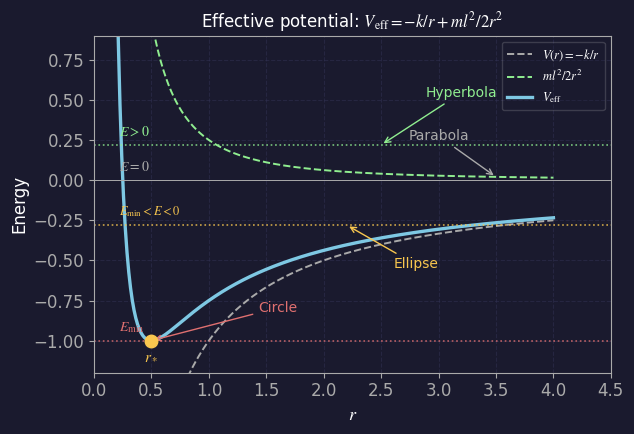

✓ figures/fig_veff.png


In [3]:
def fig_veff():
    base_style()
    fig, ax = plt.subplots(figsize=(6.5, 4.5))

    r = np.linspace(0.18, 4.0, 500)
    k, ml2 = 1.0, 0.5
    V    = -k / r
    Vcf  = ml2 / (2*r**2)
    Veff = V + Vcf

    ax.plot(r, V,    color=DIM,    lw=1.4, ls='--', label=r'$V(r)=-k/r$')
    ax.plot(r, Vcf,  color=GREEN,  lw=1.4, ls='--', label=r'$ml^2/2r^2$')
    ax.plot(r, Veff, color=BLUE,   lw=2.4, label=r'$V_\mathrm{eff}$')

    rstar = ml2 / k
    Emin  = -k**2 / (2*ml2)
    ax.plot(rstar, Emin, 'o', color=YELLOW, ms=9, zorder=5)

    # horizontal energy lines
    ax.axhline(Emin, color=RED,    lw=1.2, ls=':', alpha=0.8)
    ax.axhline(-0.28, color=YELLOW, lw=1.2, ls=':', alpha=0.8)
    ax.axhline(0,    color=DIM,    lw=0.7)
    ax.axhline(0.22, color=GREEN,  lw=1.2, ls=':', alpha=0.8)

    # r_star label
    ax.text(rstar, Emin - 0.12, r'$r_*$', color=YELLOW, fontsize=11, ha='center')

    # energy level labels — left side, well-separated
    ax.text(0.22, Emin + 0.06, r'$E_\mathrm{min}$', color=RED,    fontsize=10, ha='left')
    ax.text(0.22, -0.28 + 0.06, r'$E_\mathrm{min}<E<0$',          color=YELLOW, fontsize=9,  ha='left')
    ax.text(0.22, 0.06,         r'$E=0$',            color=DIM,    fontsize=10, ha='left')
    ax.text(0.22, 0.22 + 0.06,  r'$E>0$',            color=GREEN,  fontsize=10, ha='left')

    # orbit labels with arrows pointing to Veff curve at representative r
    ax.annotate('Circle',    xy=(rstar, Emin),  xytext=(1.6, -0.82),
                color=RED,    fontsize=10, ha='center',
                arrowprops=dict(arrowstyle='->', color=RED,    lw=1.0))
    ax.annotate('Ellipse',   xy=(2.2, -0.28),   xytext=(2.8, -0.55),
                color=YELLOW, fontsize=10, ha='center',
                arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.0))
    ax.annotate('Hyperbola', xy=(2.5,  0.22),   xytext=(3.2,  0.52),
                color=GREEN,  fontsize=10, ha='center',
                arrowprops=dict(arrowstyle='->', color=GREEN,  lw=1.0))
    ax.annotate('Parabola',  xy=(3.5,  0.02),   xytext=(3.0,  0.25),
                color=DIM,    fontsize=10, ha='center',
                arrowprops=dict(arrowstyle='->', color=DIM,    lw=1.0))

    ax.set_xlim(0, 4.5); ax.set_ylim(-1.2, 0.9)
    ax.set_xlabel(r'$r$', fontsize=13)
    ax.set_ylabel(r'Energy', fontsize=12)
    ax.set_title(r'Effective potential: $V_\mathrm{eff} = -k/r + ml^2/2r^2$',
                 color=WHITE, fontsize=12)
    ax.legend(fontsize=9, framealpha=0.2, loc='upper right')
    ax.grid(True)
    fig.tight_layout()
    fig.savefig('figures/fig_veff.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_veff.png')

fig_veff()

## Fig 3 — Stability of circular orbits: $n=1$ vs $n=3$

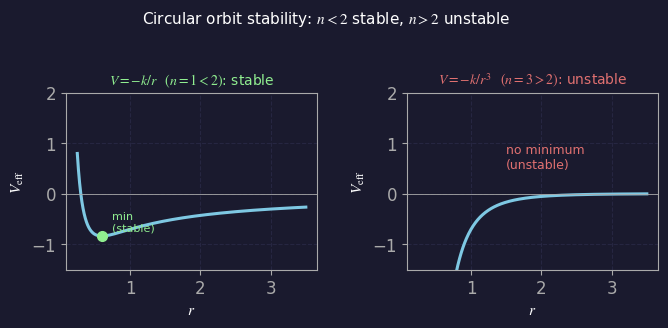

✓ figures/fig_veff_stability.png


In [4]:
def fig_veff_stability():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.2))

    r   = np.linspace(0.25, 3.5, 400)
    ml2 = 0.6
    k   = 1.0

    configs = [
        (1, r"$V=-k/r$  $(n=1<2)$: stable",   True),
        (3, r"$V=-k/r^3$  $(n=3>2)$: unstable", False),
    ]

    for ax, (n, title, stable) in zip(axes, configs):
        Veff = -k/r**n + ml2/(2*r**2)
        Veff = np.clip(Veff, -2, 3)

        col = GREEN if stable else RED
        ax.plot(r, Veff, color=BLUE, lw=2.2)
        ax.axhline(0, color=DIM, lw=0.6)
        ax.set_ylim(-1.5, 2.0)
        ax.set_xlabel(r'$r$', fontsize=11)
        ax.set_ylabel(r'$V_\mathrm{eff}$', fontsize=11)
        ax.set_title(title, color=col, fontsize=10)
        ax.grid(True)

        if stable:
            idx = np.argmin(Veff)
            ax.plot(r[idx], Veff[idx], 'o', color=GREEN, ms=7, zorder=5)
            ax.text(r[idx] + 0.15, Veff[idx] + 0.1,
                    'min\n(stable)', color=GREEN, fontsize=8)
        else:
            ax.text(1.5, 0.5, 'no minimum\n(unstable)', color=RED, fontsize=9)

    fig.suptitle('Circular orbit stability: $n<2$ stable, $n>2$ unstable',
                 color=WHITE, fontsize=11, y=1.02)
    fig.tight_layout()
    fig.savefig('figures/fig_veff_stability.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_veff_stability.png')

fig_veff_stability()

## Fig 4 — Conic sections: ellipse, parabola, hyperbola

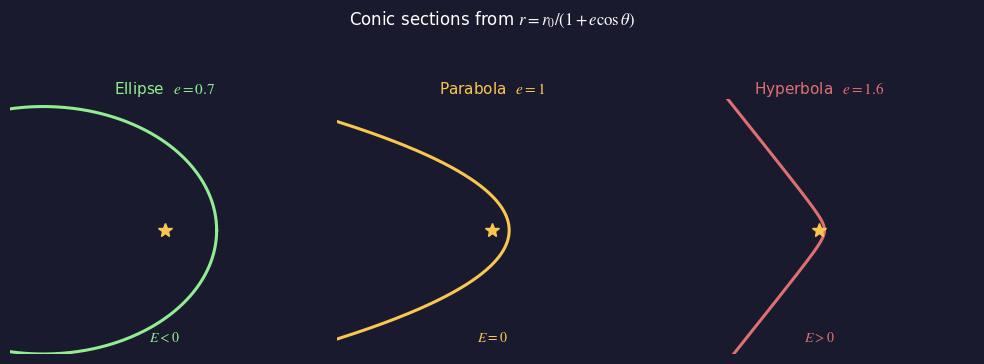

✓ figures/fig_conics.png


In [5]:
def fig_conics():
    base_style()
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.8))

    configs = [
        (0.7, 'Ellipse  $e=0.7$',   GREEN,  '$E < 0$'),
        (1.0, 'Parabola  $e=1$',    YELLOW, '$E = 0$'),
        (1.6, 'Hyperbola  $e=1.6$', RED,    '$E > 0$'),
    ]
    r0 = 1.0

    for ax, (e, title, col, elbl) in zip(axes, configs):
        ax.set_aspect('equal'); ax.axis('off')

        if e < 1:
            th = np.linspace(0, 2*np.pi, 500)
        elif e == 1:
            th = np.linspace(-2.6, 2.6, 500)
        else:
            th_max = np.arccos(-1/e) - 0.05
            th = np.linspace(-th_max, th_max, 500)

        r    = r0 / (1 + e*np.cos(th))
        mask = r > 0
        x = r[mask]*np.cos(th[mask])
        y = r[mask]*np.sin(th[mask])

        ax.plot(x, y, color=col, lw=2.2)
        ax.plot(0, 0, '*', color=YELLOW, ms=10, zorder=5)  # focus
        ax.set_title(title, color=col, fontsize=11, pad=4)

        lim = min(np.max(np.abs(x[np.isfinite(x)])),
                  np.max(np.abs(y[np.isfinite(y)]))) * 1.25
        lim = max(lim, 1.0)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim*0.8, lim*0.85)
        ax.text(0, -lim*0.72, elbl, color=col, ha='center', fontsize=10)

    fig.suptitle(r'Conic sections from $r = r_0/(1+e\cos\theta)$',
                 color=WHITE, fontsize=12, y=1.02)
    fig.tight_layout()
    fig.savefig('figures/fig_conics.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_conics.png')

fig_conics()

## Fig 5 — Elliptical orbit with labelled geometry

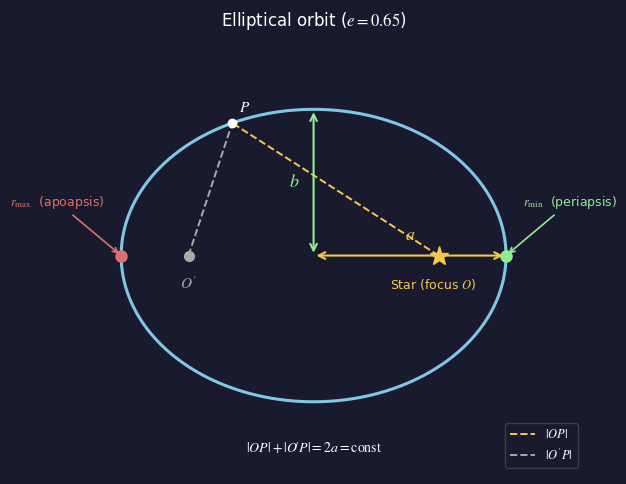

✓ figures/fig_ellipse.png


In [6]:
def fig_ellipse():
    base_style()
    fig, ax = plt.subplots(figsize=(6.5, 5.0))
    ax.set_aspect('equal'); ax.axis('off')

    e, r0 = 0.65, 1.0
    a  = r0 / (1 - e**2)
    b  = r0 / np.sqrt(1 - e**2)
    xc = -e * a   # ellipse centre (focus at origin)

    # ellipse
    th = np.linspace(0, 2*np.pi, 500)
    ax.plot(xc + a*np.cos(th), b*np.sin(th), color=BLUE, lw=2.2)

    # star (focus O) at origin
    ax.plot(0, 0, '*', color=YELLOW, ms=14, zorder=6)
    ax.text(-0.05, -0.30, 'Star (focus $O$)', color=YELLOW, fontsize=9, ha='center')

    # other focus O'
    ax.plot(2*xc, 0, 'o', color=DIM, ms=7, zorder=5)
    ax.text(2*xc, -0.30, r"$O'$", color=DIM, fontsize=11, ha='center')

    # rmin: rightmost vertex (periapsis)
    rmin_x = xc + a
    ax.plot(rmin_x, 0, 'o', color=GREEN, ms=8, zorder=5)
    ax.annotate(r'$r_\mathrm{min}$  (periapsis)',
                xy=(rmin_x, 0), xytext=(rmin_x + 0.15, 0.45),
                color=GREEN, fontsize=9, ha='left',
                arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.2))

    # rmax: leftmost vertex (apoapsis)
    rmax_x = xc - a
    ax.plot(rmax_x, 0, 'o', color=RED, ms=8, zorder=5)
    ax.annotate(r'$r_\mathrm{max}$  (apoapsis)',
                xy=(rmax_x, 0), xytext=(rmax_x - 0.15, 0.45),
                color=RED, fontsize=9, ha='right',
                arrowprops=dict(arrowstyle='->', color=RED, lw=1.2))

    # semi-major axis a: centre to right vertex
    ax.annotate('', xy=(rmin_x, 0), xytext=(xc, 0),
                arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.5))
    ax.text(xc + a/2, 0.14, r'$a$', color=YELLOW, ha='center', fontsize=13)

    # semi-minor axis b
    ax.annotate('', xy=(xc, b), xytext=(xc, 0),
                arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5))
    ax.text(xc - 0.22, b/2, r'$b$', color=GREEN, va='center', fontsize=13)

    # point P with two focal radii
    th_p = np.radians(115)
    xp = xc + a*np.cos(th_p); yp = b*np.sin(th_p)
    ax.plot(xp, yp, 'o', color=WHITE, ms=6, zorder=5)
    ax.plot([0,    xp], [0, yp], color=YELLOW, lw=1.4, ls='--', label=r'$|OP|$')
    ax.plot([2*xc, xp], [0, yp], color=DIM,    lw=1.4, ls='--', label=r"$|O'P|$")
    ax.text(xp + 0.06, yp + 0.10, r'$P$', color=WHITE, fontsize=11)

    # geometric property
    ax.text(xc, -b - 0.45,
            r'$|OP| + |O\!\prime P| = 2a = \mathrm{const}$',
            color=WHITE, fontsize=10, ha='center')

    ax.set_xlim(rmax_x - 0.7, rmin_x + 0.7)
    ax.set_ylim(-b - 0.65, b + 0.65)
    ax.set_title(r'Elliptical orbit ($e=0.65$)', color=WHITE, fontsize=12, pad=8)
    ax.legend(fontsize=9, framealpha=0.2, loc='lower right')
    fig.tight_layout()
    fig.savefig('figures/fig_ellipse.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_ellipse.png')

fig_ellipse()

## Fig 6 — Kepler's 2nd law: equal areas

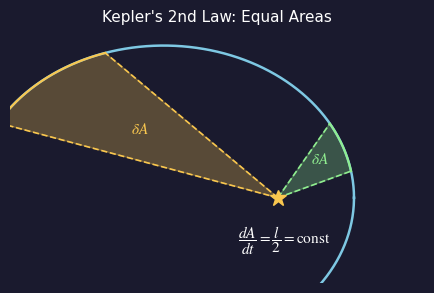

✓ figures/fig_kepler2.png


In [7]:
def fig_kepler2():
    base_style()
    fig, ax = plt.subplots(figsize=(4.5, 4.0))
    ax.set_aspect('equal'); ax.axis('off')

    e, r0 = 0.6, 1.0
    a  = r0 / (1 - e**2)
    b  = r0 / np.sqrt(1 - e**2)
    xc = -e * a

    # ellipse
    th = np.linspace(0, 2*np.pi, 500)
    ax.plot(xc + a*np.cos(th), b*np.sin(th), color=BLUE, lw=1.8)
    ax.plot(0, 0, '*', color=YELLOW, ms=12, zorder=6)

    def wedge(th1, th2, col, offset):
        """Draw a filled wedge (swept area) from focus."""
        ths = np.linspace(th1, th2, 80)
        rs  = r0 / (1 + e*np.cos(ths))
        xs  = rs*np.cos(ths); ys = rs*np.sin(ths)
        px  = np.concatenate([[0], xs, [0]])
        py  = np.concatenate([[0], ys, [0]])
        ax.fill(px, py, color=col, alpha=0.28, zorder=3)
        ax.plot(xs, ys, color=col, lw=1.5)
        ax.plot([0, xs[0]],  [0, ys[0]],  color=col, lw=1.2, ls='--')
        ax.plot([0, xs[-1]], [0, ys[-1]], color=col, lw=1.2, ls='--')
        xm = np.mean(xs)*0.55 + offset[0]
        ym = np.mean(ys)*0.55 + offset[1]
        ax.text(xm, ym, r'$\delta A$', color=col, fontsize=11, ha='center')

    wedge(np.radians(20),  np.radians(55),  GREEN,  (0.05,  0.05))
    wedge(np.radians(140), np.radians(165), YELLOW, (-0.10, 0.00))

    ax.text(0.05, -0.38,
            r'$\dfrac{dA}{dt}=\dfrac{l}{2}=\mathrm{const}$',
            color=WHITE, fontsize=11, ha='center')

    ax.set_xlim(-2.2, 1.2); ax.set_ylim(-0.7, 1.4)
    ax.set_title("Kepler's 2nd Law: Equal Areas", color=WHITE, fontsize=11, pad=4)
    fig.tight_layout()
    fig.savefig('figures/fig_kepler2.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_kepler2.png')

fig_kepler2()

## Fig 7 — Orbital precession (GR correction, exaggerated)

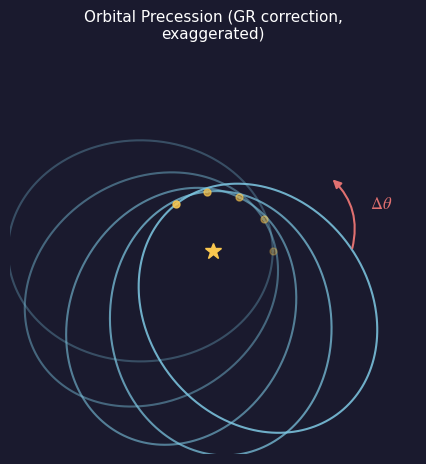

✓ figures/fig_precession.png


In [8]:
def fig_precession():
    base_style()
    fig, ax = plt.subplots(figsize=(4.8, 4.8))
    ax.set_aspect('equal'); ax.axis('off')

    e, r0 = 0.55, 1.0
    a_ell = r0 / (1 - e**2)
    b_ell = r0 / np.sqrt(1 - e**2)
    xc    = -e * a_ell

    th = np.linspace(0, 2*np.pi, 500)
    x0 = xc + a_ell*np.cos(th)
    y0 = b_ell*np.sin(th)

    # draw 5 precessed ellipses
    for i in range(5):
        phi   = i * np.radians(32)   # exaggerated precession
        xr    = x0*np.cos(phi) - y0*np.sin(phi)
        yr    = x0*np.sin(phi) + y0*np.cos(phi)
        alpha = 0.30 + 0.14*i
        ax.plot(xr, yr, color=BLUE, lw=1.5, alpha=alpha)
        # periapsis marker
        xp = (xc + a_ell)*np.cos(phi)
        yp = (xc + a_ell)*np.sin(phi)
        ax.plot(xp, yp, 'o', color=YELLOW, ms=5, alpha=alpha, zorder=5)

    # star
    ax.plot(0, 0, '*', color=YELLOW, ms=12, zorder=6)

    # precession angle arc
    ax.annotate('',
                xy=(1.5*np.cos(np.radians(32)), 1.5*np.sin(np.radians(32))),
                xytext=(1.5, 0),
                arrowprops=dict(arrowstyle='-|>', color=RED, lw=1.5,
                                connectionstyle='arc3,rad=0.3'))
    ax.text(1.7, 0.45, r'$\Delta\theta$', color=RED, fontsize=12)

    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    ax.set_title('Orbital Precession (GR correction,\nexaggerated)',
                 color=WHITE, fontsize=11, pad=6)
    fig.tight_layout()
    fig.savefig('figures/fig_precession.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_precession.png')

fig_precession()

## Fig 8 — Scattering geometry: impact parameter $b$, angles $\psi$ and $\phi$

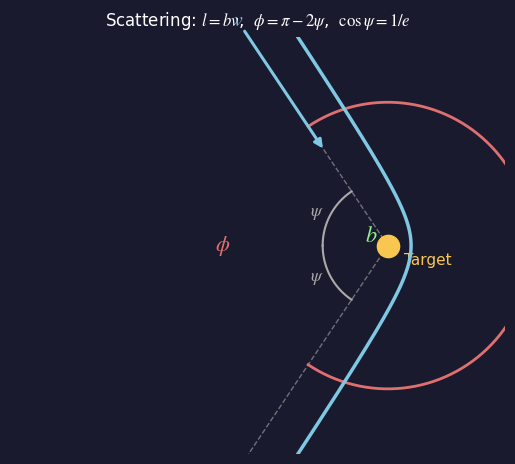

✓ figures/fig_scattering.png


In [9]:
def fig_scattering():
    base_style()
    fig, ax = plt.subplots(figsize=(7.0, 4.8))
    ax.set_aspect('equal'); ax.axis('off')

    # target at origin
    e, r0 = 1.8, 1.0
    th_max = np.arccos(-1/e) - 0.04
    th = np.linspace(-th_max, th_max, 600)
    r  = r0 / (1 + e*np.cos(th))
    ax.plot(r*np.cos(th), r*np.sin(th), color=BLUE, lw=2.5, zorder=4)

    ax.plot(0, 0, 'o', color=YELLOW, ms=16, zorder=6)
    ax.text(0.25, -0.30, 'Target', color=YELLOW, fontsize=11)

    # asymptote angle
    psi = np.arccos(1/e)
    L = 5.0
    ax.plot([0, -L*np.cos(psi)], [0,  L*np.sin(psi)], color=DIM, lw=1.0, ls='--', alpha=0.6)
    ax.plot([0, -L*np.cos(psi)], [0, -L*np.sin(psi)], color=DIM, lw=1.0, ls='--', alpha=0.6)

    # incoming beam arrow along upper asymptote
    P1 = np.array([-L*np.cos(psi)*0.8,  L*np.sin(psi)*0.8])
    P2 = np.array([-L*np.cos(psi)*0.35, L*np.sin(psi)*0.35])
    ax.annotate('', xy=P2, xytext=P1,
                arrowprops=dict(arrowstyle='-|>', color=BLUE, lw=2.2))
    ax.text(P1[0]-0.15, P1[1]+0.05, r'$v$', color=BLUE, fontsize=14)

    # impact parameter b: perpendicular from origin to incoming asymptote
    line_pt  = np.array([-L*np.cos(psi), L*np.sin(psi)])
    line_dir = np.array([np.cos(psi), -np.sin(psi)])
    t    = -np.dot(line_pt, line_dir)
    foot = line_pt + t * line_dir
    ax.annotate('', xy=foot, xytext=(0, 0),
                arrowprops=dict(arrowstyle='<->', color=GREEN, lw=2.0))
    mid = foot / 2
    ax.text(mid[0] - 0.35, mid[1] + 0.05, r'$b$', color=GREEN, fontsize=16)

    # phi arc (deflection angle)
    in_angle  =  np.pi - psi
    out_angle = -(np.pi - psi)
    arc_r = 2.2
    arc_th = np.linspace(out_angle, in_angle, 100)
    ax.plot(arc_r*np.cos(arc_th), arc_r*np.sin(arc_th), color=RED, lw=2.0)
    ax.text(-arc_r - 0.45, 0, r'$\phi$', color=RED, fontsize=16, va='center')

    # psi angle arcs (upper and lower)
    psi_arc = np.linspace(np.pi - psi, np.pi, 50)
    ax.plot(1.0*np.cos(psi_arc),  1.0*np.sin(psi_arc),  color=DIM, lw=1.5)
    ax.plot(1.0*np.cos(-psi_arc), 1.0*np.sin(-psi_arc), color=DIM, lw=1.5)
    ax.text(-1.2,  0.45, r'$\psi$', color=DIM, fontsize=13)
    ax.text(-1.2, -0.55, r'$\psi$', color=DIM, fontsize=13)

    ax.set_xlim(-5.8, 1.8); ax.set_ylim(-3.2, 3.2)
    ax.set_title(r'Scattering: $l=bv$,  $\phi=\pi-2\psi$,  $\cos\psi=1/e$',
                 color=WHITE, fontsize=12, pad=8)
    fig.tight_layout()
    fig.savefig('figures/fig_scattering.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_scattering.png')

fig_scattering()

## Fig 9 — Rutherford scattering: trajectories + $\phi(b)$ curve

<>:40: SyntaxWarning: invalid escape sequence '\p'
<>:40: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_17035/3001280520.py:40: SyntaxWarning: invalid escape sequence '\p'
  ax.set_title('Rutherford: smaller $b$ → larger $\phi$',


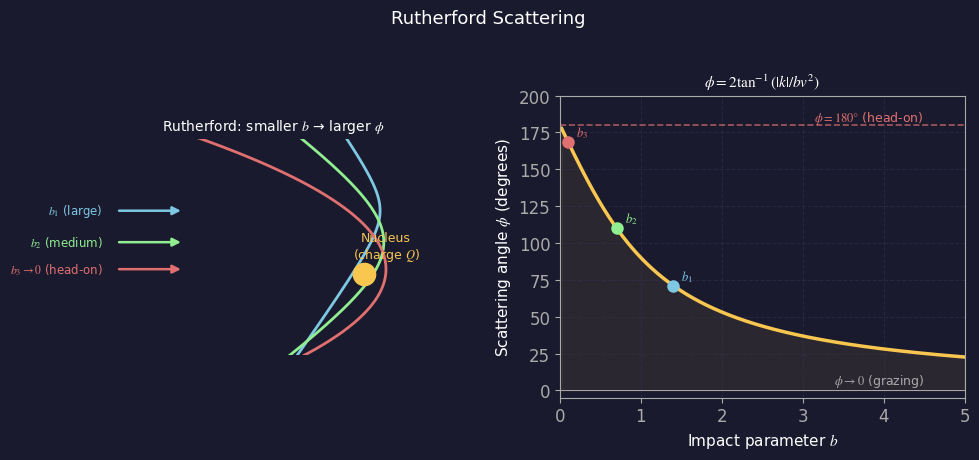

✓ figures/fig_rutherford.png


In [10]:
def fig_rutherford():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

    # ── left: three trajectories ─────────────────────────────────────────────
    ax = axes[0]
    ax.set_aspect('equal'); ax.axis('off')

    # nucleus — offset slightly so labels don't overlap trajectories
    ax.plot(0, 0, 'o', color=YELLOW, ms=16, zorder=6)
    ax.text(0.5, 0.35, 'Nucleus\n(charge $Q$)', color=YELLOW,
            fontsize=9, ha='center', zorder=7)

    k_val, v_val = 1.0, 1.0
    configs = [
        (1.4, BLUE,  r'$b_1$ (large)'),
        (0.7, GREEN, r'$b_2$ (medium)'),
        (0.1, RED,   r'$b_3 \to 0$ (head-on)'),
    ]

    for b_val, col, lbl in configs:
        e_val  = np.sqrt(1 + (b_val * v_val**2 / k_val)**2)
        r0_val = k_val / v_val**2
        th_max = np.arccos(-1/e_val) - 0.02
        th = np.linspace(-th_max, th_max, 600)
        r  = r0_val / (1 + e_val*np.cos(th))
        # shift vertically by b so beam arrives at height b
        x  = r * np.cos(th)
        y  = r * np.sin(th) + b_val

        ax.plot(x, y, color=col, lw=2.0, zorder=4)

        # incoming arrow far left
        ax.annotate('', xy=(-4.0, b_val), xytext=(-5.5, b_val),
                    arrowprops=dict(arrowstyle='-|>', color=col, lw=1.8))
        ax.text(-5.8, b_val, lbl, color=col, fontsize=8.5,
                va='center', ha='right')

    ax.set_xlim(-6.5, 2.5); ax.set_ylim(-1.8, 3.0)
    ax.set_title('Rutherford: smaller $b$ → larger $\phi$',
                 color=WHITE, fontsize=10, pad=6)

    # ── right: phi vs b curve ─────────────────────────────────────────────────
    ax = axes[1]
    b   = np.linspace(0.02, 5, 500)
    phi = 2 * np.arctan(k_val / (b * v_val**2))

    ax.plot(b, np.degrees(phi), color=YELLOW, lw=2.5)
    ax.axhline(180, color=RED, lw=1.2, ls='--', alpha=0.7)
    ax.axhline(0,   color=DIM, lw=0.7)

    ax.fill_between(b, np.degrees(phi), 0, alpha=0.08, color=YELLOW)

    ax.text(4.5, 183, r'$\phi = 180°$ (head-on)', color=RED,   fontsize=9, ha='right')
    ax.text(4.5,   4, r'$\phi \to 0$ (grazing)',  color=DIM,   fontsize=9, ha='right')

    # mark specific b values
    for b_val, col, lbl in [(1.4, BLUE, '$b_1$'), (0.7, GREEN, '$b_2$'),
                             (0.1, RED,  '$b_3$')]:
        phi_val = np.degrees(2*np.arctan(k_val/(b_val*v_val**2)))
        ax.plot(b_val, phi_val, 'o', color=col, ms=8, zorder=5)
        ax.text(b_val + 0.1, phi_val + 4, lbl, color=col, fontsize=9)

    ax.set_xlabel(r'Impact parameter $b$', fontsize=11)
    ax.set_ylabel(r'Scattering angle $\phi$ (degrees)', fontsize=11)
    ax.set_title(r'$\phi = 2\tan^{-1}(|k|/bv^2)$', color=WHITE, fontsize=11)
    ax.set_xlim(0, 5); ax.set_ylim(-5, 200)
    ax.grid(True)

    fig.suptitle('Rutherford Scattering', color=WHITE, fontsize=13, y=1.02)
    fig.tight_layout()
    fig.savefig('figures/fig_rutherford.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_rutherford.png')

fig_rutherford()

---
## Download all figures as zip

In [11]:
import shutil
from google.colab import files

shutil.make_archive('figures_ch04', 'zip', '.', 'figures')
files.download('figures_ch04.zip')
print('✓ figures_ch04.zip downloaded')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ figures_ch04.zip downloaded
